# 05 · Can We Trust the LLM Labels?

Before using the 1,000 LLM labels for any business conclusion, they are checked against **100 reviews labeled by hand**
(`data/labels/manual_100.csv`). The 100 reviews are a random subset of the 1,000, and the LLM sessions never saw the hand labels.

**Target from the problem statement:** at least 85% agreement on the primary label.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score, confusion_matrix

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED})

human = pd.read_csv("../data/labels/manual_100.csv")
llm = pd.read_csv("../data/labels/llm_labels_1000.csv")
df = human.merge(llm.drop(columns="review_text"), on="review_id", suffixes=("_human", "_llm"))
df["agree"] = df["primary_label_human"] == df["primary_label_llm"]
print(f"Reviews compared: {len(df)}")

Reviews compared: 100


## 1. Agreement

In [2]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

k, n = df["agree"].sum(), len(df)
low, high = wilson(k, n)
kappa = cohen_kappa_score(df["primary_label_human"], df["primary_label_llm"])
flag = (df["seller_unresponsive_human"] == df["seller_unresponsive_llm"]).mean()

print(f"Primary label agreement: {k}/{n} = {k/n:.0%}  (95% CI {low:.0%}–{high:.0%})")
print(f"Cohen's kappa: {kappa:.2f}  (agreement corrected for chance)")
print(f"seller_unresponsive flag agreement: {flag:.0%}")

Primary label agreement: 93/100 = 93%  (95% CI 86%–97%)
Cohen's kappa: 0.92  (agreement corrected for chance)
seller_unresponsive flag agreement: 92%


## 2. Where do they disagree?
Rows: hand label. Columns: LLM label. Everything off the diagonal is a disagreement.

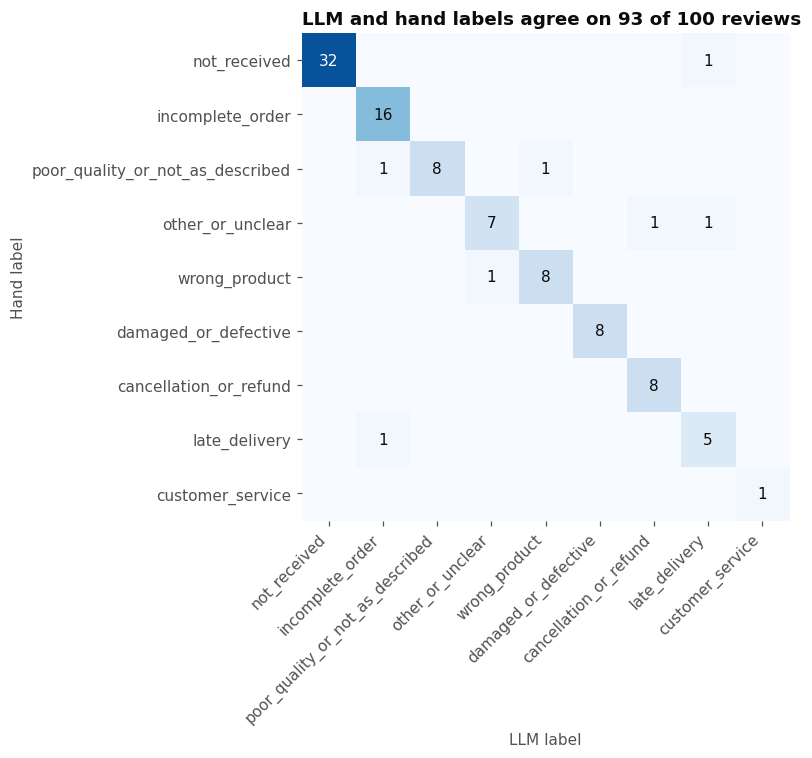

In [3]:
order = list(df["primary_label_human"].value_counts().index)
order += [l for l in df["primary_label_llm"].unique() if l not in order]
cm = confusion_matrix(df["primary_label_human"], df["primary_label_llm"], labels=order)

fig, ax = plt.subplots(figsize=(8.5, 7))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.15)
for i in range(len(order)):
    for j in range(len(order)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else INK, fontsize=10)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=45, ha="right")
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_xlabel("LLM label"); ax.set_ylabel("Hand label")
ax.set_title(f"LLM and hand labels agree on {k} of {n} reviews", loc="left", color=INK, fontsize=12, fontweight="bold")
for s in ax.spines.values(): s.set_visible(False)
plt.tight_layout()
plt.savefig("../outputs/08_label_agreement_matrix.png", bbox_inches="tight")
plt.show()

## 3. Does the LLM know when it is unsure?

In [4]:
by_conf = df.groupby("confidence").agg(reviews=("agree", "size"), agreement=("agree", "mean"))
print(by_conf.style.format({"agreement": "{:.0%}"}).to_string())
print(f"\nHuman marked 'unsure' on {df['unsure'].sum()} reviews; agreement there: {df.loc[df['unsure'], 'agree'].mean():.0%}")

 reviews agreement
confidence  
high 88 97%
low 12 67%


Human marked 'unsure' on 3 reviews; agreement there: 67%


## 4. Adjudication of the disagreements
Each disagreement was reviewed by the hand labeler against the written taxonomy rules, with three possible verdicts:
the LLM followed the rules, the human did, or the rules did not cover the case.

**The hand labels were not changed.** The agreement above stays the official number; adjudication is reported separately.

In [5]:
adj = pd.read_csv("../data/labels/adjudication.csv")
pd.set_option("display.max_colwidth", 80)
print(adj["verdict"].value_counts().to_string())
adj[["review_text", "primary_label_human", "primary_label_llm", "verdict", "note"]]

verdict
llm_correct      5
rule_unclear     1
human_correct    1


,review_text,primary_label_human,primary_label_llm,verdict,note
0,Produto q n tinha na loja..receber n um produto q n gostei..,wrong_product,other_or_unclear,llm_correct,Text does not say a different product was sent; reason unclear
1,"Na foto mostrava duas suspensão, e nas descrição dizia um, logo entendi um par.",poor_quality_or_not_as_described,incomplete_order,llm_correct,"Listing photo showed two, customer received one"
2,"NAO GOSTE DESSA COMPRA. RECEBI O ESTOJO, BEM DEPOIS AANCHEIRA E AINDA NAO RE...",late_delivery,incomplete_order,llm_correct,"Backpack still missing while other items arrived: incomplete, not late"
3,veio um lustre totalmente diferente do solicitado.,poor_quality_or_not_as_described,wrong_product,llm_correct,"""Different from what I ordered"" means another model was sent"
4,Entrega atrasada sera que é correios em greve?,not_received,late_delivery,rule_unclear,"Delay complaint, arrival unknown; rule added: still waiting -> not_received"
5,Estoque do parceiro zerado.,other_or_unclear,cancellation_or_refund,llm_correct,Out of stock falls under cancellation_or_refund
6,"Quando eu fui comprar o produto,me falaram q viria em uma data,após a compra...",other_or_unclear,late_delivery,human_correct,"Several unrelated complaints, none clearly the main one"


In [6]:
llm_wrong = (adj["verdict"] == "human_correct").sum()
human_wrong = (adj["verdict"] == "llm_correct").sum()
unclear = (adj["verdict"] == "rule_unclear").sum()
print(f"After adjudication, the LLM followed the rules on {n - llm_wrong - unclear}/{n} reviews,")
print(f"the hand labels on {n - human_wrong - unclear}/{n}, and {unclear} review(s) exposed a gap in the rules.")

After adjudication, the LLM followed the rules on 98/100 reviews,
the hand labels on 94/100, and 1 review(s) exposed a gap in the rules.


## Verdict

- **The LLM labels pass the bar.** 93% agreement with the hand labels (95% CI 86%–97%) against a target of 85%, with a Cohen's kappa that shows this is far above chance.
- **The LLM flags its own hard cases.** Agreement is clearly lower on reviews it marked as low confidence, so low-confidence labels can be routed to a human in a production setup.
- **Disagreements were mostly human slips, not model errors.** In adjudication the LLM followed the written rules in 5 of the 7 disagreements, the human in 1, and 1 case revealed a missing rule, which was added to the taxonomy.
- Labeling 100 reviews by hand also surfaced two other gaps in the rules (packaging and customer-service scope). Testing the rules on real reviews before scaling up was worth the time.

**Limitations**
- 100 reviews give a wide confidence interval; rare labels (`customer_service`, `delivery_service`) have too few examples to judge on their own.
- Adjudication was done by the same person who made the hand labels.
- The rule for "late, arrival unknown" was added after the LLM run. Some of the LLM's `late_delivery` labels may be `not_received` under the new rule. Both are delivery failures, so the impact analysis reports them together as well as separately.

**Decision:** use the 1,000 LLM labels for the impact analysis (notebook 06).